# Katzen oder Brötchen: Model Inference & Interactive Image Tester
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/postelzhuktetyana/katzen-oder-broetchen/blob/main/cat_or_bun_tester.ipynb)

**Coursework Project**: Computer Vision Image Classification using FastAI & Deep Transfer Learning  
**Companion to**: [`cat_or_bun_classifier.ipynb`](cat_or_bun_classifier.ipynb)  
**Trained Model Asset**: `models/cat_or_bun_model.pkl`

---

### Notebook Overview
This notebook provides a dedicated, lightweight **inference and diagnostic workspace** for the trained "Cat or Bun" model. Rather than executing the full data collection, augmentation, and fine-tuning pipelines, this notebook loads the exported learner bundle (`models/cat_or_bun_model.pkl`) independently to classify any custom image chosen from your local filesystem or dragged-and-dropped in your browser.

### Key Capabilities
1. **Decoupled Inference**: Loads the serialized `.pkl` bundle using FastAI's `load_learner()` without requiring original training DataLoaders or dataset directories.
2. **Multi-Class Softmax Distribution**: Visualizes confidence percentages across all classes (e.g. `92.4% Cat, 7.6% Bun`) with custom color-coded horizontal bar plots.
3. **Ambiguity Diagnostics**: Detects visually challenging "cat loaf" edge cases where model confidence is distributed close to 50/50.
4. **Multiple Ways to Choose Images**:
   - **Interactive Dropdown**: Select test images from `testing_images/` or any custom folder.
   - **Direct Path Entry**: Enter an absolute or relative path to any image file on your computer.
   - **Drag-and-Drop Browser Uploader**: Use `ipywidgets.FileUpload` to test new photos directly from your browser.
   - **Batch Folder Evaluation**: Process an entire folder of test images and render an annotated visual gallery grid.


## 1. Environment Setup & Library Imports

### 1. Practical Goal
Prepare the runtime environment for model inference by loading essential computer vision libraries, interactive widgets, and visualization tools.

### 2. Core ML Concept: Decoupling Training and Inference
In real-world machine learning engineering, model inference is isolated from the training pipeline. The training dependencies (large datasets, data augmentations, optimizer updates, loss functions) are not needed at runtime. Inference only requires the learned weights, network architecture, and evaluation preprocessing transforms.

### 3. Python & FastAI Implementation Details
* `import fastai; from fastai.vision.all import *`: Imports FastAI's vision inference components (`load_learner`, `PILImage`).
* `import ipywidgets as widgets`: Interactive UI widgets for file selection, buttons, and drag-and-drop file upload.
* `import matplotlib.pyplot as plt`: Visual plotting library for side-by-side image display and probability bar charts.


In [1]:
import io
import warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

# Silence PyTorch's internal TorchScript deprecation warning triggered on FastAI import
warnings.filterwarnings("ignore", category=FutureWarning, message=r".*torch\.jit\.script.*")

import fastai
from fastai.vision.all import *

print(f"FastAI version: {fastai.__version__}")
print(f"PyTorch version: {torch.__version__}")
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Active inference device: {device.upper()}")


FastAI version: 2.8.12
PyTorch version: 2.15.0+cu132
Active inference device: CPU


## 2. Model Bundle Inspection & Loading

### 1. Practical Goal
Locate and deserialize the trained model bundle `models/cat_or_bun_model.pkl` using FastAI's `load_learner()` function and verify the class vocabulary.

### 2. Core ML Concept: Learner Serialization & Inference Mode
`load_learner()` reconstructs the PyTorch model architecture, restores the trained numerical weights (tensors), and reinstates the evaluation transform pipeline. The model is automatically set to evaluation mode (`model.eval()`), disabling dropout and freezing batch normalization statistics for deterministic predictions.

### 3. Python & FastAI Implementation Details
* `load_learner(model_path, cpu=...)`: Restores the exported `Learner` bundle on CPU or GPU without requiring the original training dataset.
* `learn_inf.dls.vocab`: Accesses the category vocabulary list (e.g. `['bun', 'cat']`) learned during training.


In [2]:
model_path = Path('models/cat_or_bun_model.pkl')

if not model_path.exists():
    raise FileNotFoundError(
        f"Model not found at '{model_path}'.\n"
        f"Copy 'cat_or_bun_model.pkl' from your Colab/Kaggle 'models/' folder here."
    )

file_size_mb = model_path.stat().st_size / (1024 * 1024)
print(f"Found model: {model_path} ({file_size_mb:.2f} MB)")

learn_inf = load_learner(model_path, cpu=(device == 'cpu'))

vocab = list(learn_inf.dls.vocab)
print("Model loaded successfully!")
print(f"Architecture : {learn_inf.model.__class__.__name__}")
print(f"Vocabulary   : {vocab}")


Found model: models/cat_or_bun_model.pkl (83.43 MB)
Model loaded successfully!
Architecture : Sequential
Vocabulary   : ['bun', 'cat']


/home/andre/miniforge3/envs/katzen/lib/python3.13/site-packages/fastai/learner.py:456: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


## 3. Core Prediction Engine & Softmax Visualization

### 1. Practical Goal
Implement a robust inference function `predict_and_display()` that accepts any image source (file path, raw bytes, or PIL Image), computes normalized Softmax confidence percentages, and renders a side-by-side visual display with a horizontal probability bar chart.

### 2. Core ML Concept: Softmax Distribution & Visual Ambiguity
Traditional classifiers often reduce predictions to a binary boolean (`is_cat: True/False`). However, in visual ambiguity tasks like "Cats vs. Buns," binary decisions discard critical confidence nuance. 

The **Softmax function** normalizes raw logit outputs into a probability distribution summing to 1.0 (100%):
$$\sigma(z)_i = \frac{e^{z_i}}{\sum_{j=1}^K e^{z_j}}$$

When an image presents visual characteristics of both categories (e.g. a sleeping curled-up orange cat with tucked paws), the model outputs balanced confidence scores (e.g. 56% Cat, 44% Bun). We identify and flag these as **Ambiguous Edge Cases**.

### 3. Python & FastAI Implementation Details
* `PILImage.create(source)`: Flexible FastAI constructor accepting file paths, raw byte streams, or PIL images.
* `learn_inf.predict(img)`: Computes the predicted class string, integer index, and tensor of class probabilities.
* `plt.subplots(1, 2, figsize=(10, 4.2))`: Matplotlib side-by-side canvas rendering the image and horizontal probability bar chart.


In [3]:
def predict_and_display(img_source, title_label=None):
    """
    Run inference on an input image and display a dual visualization:
    Left: Input image preview.
    Right: Horizontal probability bar chart annotated with percentage confidence.
    
    Args:
        img_source: Path (str/Path), file-like buffer, or raw bytes of the image.
        title_label (str, optional): Custom title or filename to display above the image.
    """
    try:
        # Load image via FastAI PILImage (supports Path, byte stream, or PIL Image)
        if isinstance(img_source, (bytes, bytearray)):
            img = PILImage.create(io.BytesIO(img_source))
        else:
            img = PILImage.create(img_source)
    except Exception as e:
        print(f"❌ Error loading image: {e}")
        return None

    # Compute model prediction
    pred_class, pred_idx, probs = learn_inf.predict(img)
    vocab = learn_inf.dls.vocab
    
    # Construct category probability dictionary
    prob_dict = {cat.capitalize(): float(probs[i]) for i, cat in enumerate(vocab)}
    top_cat = pred_class.capitalize()
    top_conf = prob_dict[top_cat] * 100.0
    
    # Measure visual ambiguity (difference between top and second class)
    sorted_probs = sorted(prob_dict.values(), reverse=True)
    prob_margin = (sorted_probs[0] - sorted_probs[1]) * 100.0 if len(sorted_probs) > 1 else 100.0
    
    # Display text summary
    display_title = title_label or (Path(img_source).name if isinstance(img_source, (str, Path)) else "Input Image")
    print("=" * 52)
    print(f" Image:       {display_title}")
    print(f" Prediction:  {top_cat.upper()} ({top_conf:.1f}% confidence)")
    if prob_margin < 25.0:
        print(f" ⚠️ High Ambiguity: Margin is only {prob_margin:.1f}% (Classic Cat Loaf Case!)")
    print("-" * 52)
    for cat, p in prob_dict.items():
        print(f"   • {cat:<6}: {p * 100.0:5.1f}%")
    print("=" * 52)

    # Render side-by-side visualization
    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={'width_ratios': [1.1, 1.3]})
    
    # Left subplot: Display image
    ax_img.imshow(img)
    ax_img.set_title(f"Input: {display_title}", fontsize=11, fontweight='bold', pad=10)
    ax_img.axis('off')
    
    # Right subplot: Horizontal probability bar chart
    categories = list(prob_dict.keys())
    values = [prob_dict[c] * 100.0 for c in categories]
    # Pastel colors: warm coral for Cat, golden wheat for Bun
    colors = ['#ff8566' if c == 'Cat' else '#e6b800' for c in categories]
    
    bars = ax_bar.barh(categories, values, color=colors, edgecolor='#333333', height=0.45)
    ax_bar.set_xlim(0, 100)
    ax_bar.set_xlabel('Model Confidence (%)', fontsize=10, labelpad=8)
    ax_bar.set_title('Softmax Category Probabilities', fontsize=11, fontweight='bold', pad=10)
    ax_bar.grid(axis='x', linestyle='--', alpha=0.5)
    
    # Annotate percentage text on bars
    for bar in bars:
        w = bar.get_width()
        ax_bar.text(w + 2.0, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%",
                    va='center', ha='left', fontsize=10, fontweight='bold', color='#222222')
    
    plt.tight_layout()
    plt.show()
    return prob_dict


## 4. Quick Sanity Test on Sample Image

### 1. Practical Goal
Validate the inference pipeline against the tracked external test image `testing_images/katzebroetchen.jpg`.

### 2. Core ML Concept: Edge-Case Evaluation
Testing on external, uncurated images tests whether the model's learned feature representations generalize beyond web-scraped training data. `katzebroetchen.jpg` features an ambiguous hybrid scene specifically designed to evaluate classification under visual uncertainty.

### 3. Python & FastAI Implementation Details
* Checks if `testing_images/katzebroetchen.jpg` exists locally (or pulls from `data/cats_and_buns/` fallback).
* Calls `predict_and_display()`.


Testing on external sample image: testing_images/katzebroetchen.jpg


 Image:       katzebroetchen.jpg
 Prediction:  CAT (99.9% confidence)
----------------------------------------------------
   • Bun   :   0.1%
   • Cat   :  99.9%


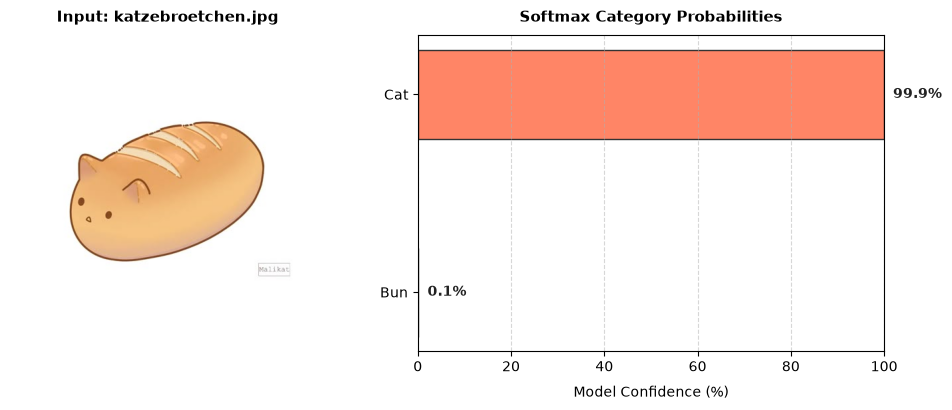

In [4]:
# Test on the standard external test image if present
test_path = Path('testing_images/katzebroetchen.jpg')

if test_path.exists():
    print(f"Testing on external sample image: {test_path}")
    predict_and_display(test_path)
else:
    # Fallback to any image from the downloaded dataset
    dataset_images = get_image_files('data/cats_and_buns') if Path('data/cats_and_buns').exists() else L()
    if len(dataset_images) > 0:
        sample_img = dataset_images[0]
        print(f"Testing on sample dataset image: {sample_img}")
        predict_and_display(sample_img)
    else:
        print("No test images found. Use the interactive picker below to choose an image from your filesystem!")


## 5. Interactive Filesystem Image Picker

### 1. Practical Goal
Provide an interactive GUI widget allowing users to select any image from `testing_images/`, the `data/` directory, or by typing an arbitrary file path from their filesystem.

### 2. Core ML Concept: Human-in-the-Loop Model Auditing
Interactive visual inspectors allow researchers, students, and domain experts to test arbitrary edge cases interactively, diagnosing blind spots (such as lighting changes, background textures, or unusual camera angles) without writing repetitive Python scripts.

### 3. Python & FastAI Implementation Details
* `widgets.Dropdown`: Dropdown menu listing all discoverable image files.
* `widgets.Text`: Freeform text box to input any arbitrary file path on your computer.
* `widgets.Button`: Interactive execution trigger.
* `widgets.Output`: Dedicated container for rendering the prediction results dynamically.


In [5]:
# Discover all image files across testing_images and data directories
discovered_files = []
for search_dir in [Path('testing_images'), Path('data/cats_and_buns')]:
    if search_dir.exists():
        discovered_files.extend(get_image_files(search_dir))

file_options = [(f"{f.parent.name}/{f.name}", str(f)) for f in discovered_files]
if not file_options:
    file_options = [("No discovered images", "")]

# Construct interactive widgets
dropdown = widgets.Dropdown(
    options=file_options,
    description='Select File:',
    layout=widgets.Layout(width='60%')
)

custom_path_input = widgets.Text(
    value='',
    placeholder='Or type any path on your machine (e.g. /home/user/Pictures/my_cat.jpg)',
    description='Custom Path:',
    layout=widgets.Layout(width='85%')
)

classify_btn = widgets.Button(
    description='🔍 Classify Image',
    button_style='primary',
    tooltip='Run model inference on the selected image',
    icon='search',
    layout=widgets.Layout(width='200px', height='38px')
)

output_area = widgets.Output()

def on_classify_clicked(b):
    with output_area:
        clear_output()
        # Priority: custom path if filled, otherwise dropdown selection
        target_path = custom_path_input.value.strip() or dropdown.value
        if not target_path:
            print("⚠️ Please select an image from the dropdown or enter a valid file path.")
            return
            
        img_p = Path(target_path)
        if not img_p.exists():
            print(f"❌ File not found at: {img_p.resolve()}")
            return
            
        predict_and_display(img_p, title_label=img_p.name)

classify_btn.on_click(on_classify_clicked)

# Display the control dashboard
print("📁 Choose an image from the dropdown or enter any path from your computer:")
display(widgets.VBox([
    dropdown,
    custom_path_input,
    classify_btn,
    output_area
]))


📁 Choose an image from the dropdown or enter any path from your computer:


## 6. Drag-and-Drop In-Browser File Uploader

### 1. Practical Goal
Allow users to upload or drag-and-drop any image file directly from their desktop or file explorer into the Jupyter interface for instant classification.

### 2. Core ML Concept: Web-Like Prototyping
Interactive upload widgets bridge the gap between static notebooks and live web deployment (such as Gradio or Streamlit apps), allowing non-technical evaluators to interact directly with the model.

### 3. Python & FastAI Implementation Details
* `widgets.FileUpload(accept='image/*', multiple=False)`: Native browser file selector widget.
* Robust decoding supporting both `ipywidgets 7.x` (dictionary structure) and `ipywidgets 8.x` (tuple of file objects).
* Direct byte stream ingestion via `io.BytesIO()`.


In [ ]:
uploader = widgets.FileUpload(
    accept='image/*',      # Restrict to image file formats
    multiple=False,        # Single file upload
    description='📤 Upload Image',
    button_style='success',
    layout=widgets.Layout(width='220px', height='38px')
)

upload_output = widgets.Output()

def on_upload_change(change):
    with upload_output:
        clear_output()
        if not uploader.value:
            return
            
        file_bytes = None
        file_name = "Uploaded Image"
        
        # Handle both ipywidgets 7.x and 8.x formats
        val = uploader.value
        if isinstance(val, dict):  # ipywidgets 7.x
            first_key = next(iter(val))
            file_name = first_key
            file_bytes = val[first_key]['content']
        elif isinstance(val, (list, tuple)) and len(val) > 0:  # ipywidgets 8.x
            item = val[0]
            file_name = getattr(item, 'name', 'Uploaded Image')
            if isinstance(item, dict):
                file_bytes = item.get('content')
            elif hasattr(item, 'content'):
                file_bytes = bytes(item.content)
            elif hasattr(item, 'tobytes'):
                file_bytes = item.tobytes()
                
        if file_bytes:
            print(f"✓ Received uploaded file: '{file_name}' ({len(file_bytes)} bytes)")
            predict_and_display(file_bytes, title_label=file_name)
        else:
            print("⚠️ Could not read uploaded file content.")

uploader.observe(on_upload_change, names='value')

print("📤 Click below to upload or drag-and-drop an image from your computer:")
display(widgets.VBox([uploader, upload_output]))


## 7. Batch Evaluation & Annotated Gallery Grid

### 1. Practical Goal
Evaluate an entire folder of test images in a single batch pass, generating an annotated gallery grid displaying input images, predicted labels, and confidence tags.

### 2. Core ML Concept: Batch Inference & Error Surface Inspection
Auditing a diverse collection of images simultaneously allows quick visual inspection of error distributions and systematic biases (e.g. consistently mistaking round cinnamon buns for sleeping cats).

### 3. Python & FastAI Implementation Details
* `get_image_files(folder)`: Recursively retrieves all valid image file paths.
* Multi-panel Matplotlib grid layout with color-coded title badges (green for high-confidence predictions, amber for ambiguous cases).


In [ ]:
def test_directory_gallery(folder_path='testing_images', max_images=8):
    """
    Evaluate all images in a target directory and render an annotated visual gallery grid.
    
    Args:
        folder_path (str or Path): Directory containing test images.
        max_images (int): Maximum number of images to render in the gallery.
    """
    p = Path(folder_path)
    if not p.exists():
        print(f"Directory '{p}' does not exist.")
        return
        
    imgs = get_image_files(p)[:max_images]
    if len(imgs) == 0:
        print(f"No image files found in '{p}'.")
        return
        
    n = len(imgs)
    cols = min(4, n)
    rows = (n + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.2, rows * 3.4))
    axes = np.array(axes).reshape(-1) # Flatten axes array for 1D indexing
    
    print(f"📊 Batch Inference Gallery: Evaluating {n} images from '{p}'...")
    
    for i, img_path in enumerate(imgs):
        ax = axes[i]
        try:
            pil_img = PILImage.create(img_path)
            pred_class, pred_idx, probs = learn_inf.predict(pil_img)
            conf = float(probs[pred_idx]) * 100.0
            
            ax.imshow(pil_img)
            # Color code title: green for decisive (>80%), amber for ambiguous
            title_color = '#006600' if conf >= 80.0 else '#b35900'
            ax.set_title(f"{pred_class.upper()} ({conf:.1f}%)\n{img_path.name[:18]}", 
                         fontsize=9, fontweight='bold', color=title_color)
            ax.axis('off')
        except Exception as e:
            ax.set_title("Error", fontsize=9, color='red')
            ax.axis('off')
            
    # Hide unused subplots
    for j in range(n, len(axes)):
        axes[j].axis('off')
        
    plt.tight_layout()
    plt.show()

# Run batch gallery evaluation on testing_images
test_directory_gallery('testing_images', max_images=8)
